# Solution: Mission 01 — E-Commerce Analytics Warehouse

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        if "$$" in sql:                       # function bodies contain ";" -> send the whole script at once
            conn.execute(text(sql))
            return
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

REGION = {
    "USA": "North America", "Canada": "North America",
    "Brazil": "South America", "Argentina": "South America", "Chile": "South America",
    "India": "Asia-Pacific", "Australia": "Asia-Pacific",
}   # every other Chinook country is in Europe

## Task 1: Schema

Grain of `fact_sales`: **one track sold on one invoice line**. Dimensions get integer surrogate keys; the source ids stay as attributes, so the warehouse can be reloaded and traced back to the source.

In [2]:
run("""
DROP SCHEMA IF EXISTS mart CASCADE;
CREATE SCHEMA mart;
CREATE TABLE mart.dim_customer (
    customer_key int PRIMARY KEY, customer_id int NOT NULL UNIQUE,
    customer_name text NOT NULL, country text NOT NULL, region text NOT NULL);
CREATE TABLE mart.dim_product (
    product_key int PRIMARY KEY, track_id int NOT NULL UNIQUE,
    track text NOT NULL, album text NOT NULL, artist text NOT NULL, genre text NOT NULL);
CREATE TABLE mart.dim_date (
    date_key int PRIMARY KEY, date date NOT NULL UNIQUE, year int, quarter int, month int, month_start date);
CREATE TABLE mart.fact_sales (
    invoice_line_id int PRIMARY KEY,
    invoice_id int NOT NULL,
    date_key int NOT NULL REFERENCES mart.dim_date,
    customer_key int NOT NULL REFERENCES mart.dim_customer,
    product_key int NOT NULL REFERENCES mart.dim_product,
    quantity int NOT NULL CHECK (quantity > 0),
    revenue numeric(10, 2) NOT NULL)
""")
print(lq("SELECT table_name FROM information_schema.tables WHERE table_schema = 'mart' ORDER BY 1")["table_name"].tolist())

['dim_customer', 'dim_date', 'dim_product', 'fact_sales']


## Task 2: Load and Reconcile

In [3]:
cust = q("SELECT customer_id, first_name || ' ' || last_name AS customer_name, country FROM customer ORDER BY customer_id")
cust.insert(0, "customer_key", range(1, len(cust) + 1))
cust["region"] = cust["country"].map(REGION).fillna("Europe")

prod = q("""SELECT t.track_id, t.name AS track, al.title AS album, ar.name AS artist, g.name AS genre
            FROM track t JOIN album al USING (album_id) JOIN artist ar USING (artist_id) JOIN genre g USING (genre_id)
            ORDER BY t.track_id""")
prod.insert(0, "product_key", range(1, len(prod) + 1))

days = pd.date_range("2021-01-01", "2025-12-31", freq="D")
dates = pd.DataFrame({"date_key": days.strftime("%Y%m%d").astype(int), "date": days.date, "year": days.year,
                      "quarter": days.quarter, "month": days.month, "month_start": days.to_period("M").start_time.date})

lines = q("""SELECT il.invoice_line_id, il.invoice_id, i.invoice_date::date AS d, i.customer_id, il.track_id,
                    il.quantity, il.unit_price * il.quantity AS revenue
             FROM invoice_line il JOIN invoice i USING (invoice_id)""")
fact = (lines.merge(cust[["customer_key", "customer_id"]], on="customer_id")
             .merge(prod[["product_key", "track_id"]], on="track_id"))
fact["date_key"] = pd.to_datetime(fact["d"]).dt.strftime("%Y%m%d").astype(int)

for name, df in [("dim_customer", cust), ("dim_product", prod), ("dim_date", dates),
                 ("fact_sales", fact[["invoice_line_id", "invoice_id", "date_key", "customer_key", "product_key",
                                      "quantity", "revenue"]])]:
    df.to_sql(name, lab, schema="mart", if_exists="append", index=False)

source_total = q("SELECT sum(total) AS t FROM invoice")["t"][0]
mart_total = lq("SELECT sum(revenue) AS t FROM mart.fact_sales")["t"][0]
print(f"fact rows: {len(fact):,} | source revenue {source_total} | mart revenue {mart_total} | match: {source_total == mart_total}")
print(cust["region"].value_counts().to_dict())

fact rows: 2,240 | source revenue 2328.6 | mart revenue 2328.6 | match: True
{'Europe': 28, 'North America': 21, 'South America': 7, 'Asia-Pacific': 3}


## Task 3: Monthly Revenue per Region with a Running Total

month_start       region  revenue  running_total
 2021-04-01 Asia-Pacific     5.94           5.94
 2021-07-01 Asia-Pacific     9.90          15.84
 2021-10-01 Asia-Pacific     5.94          21.78
 2022-02-01 Asia-Pacific     1.99          23.77


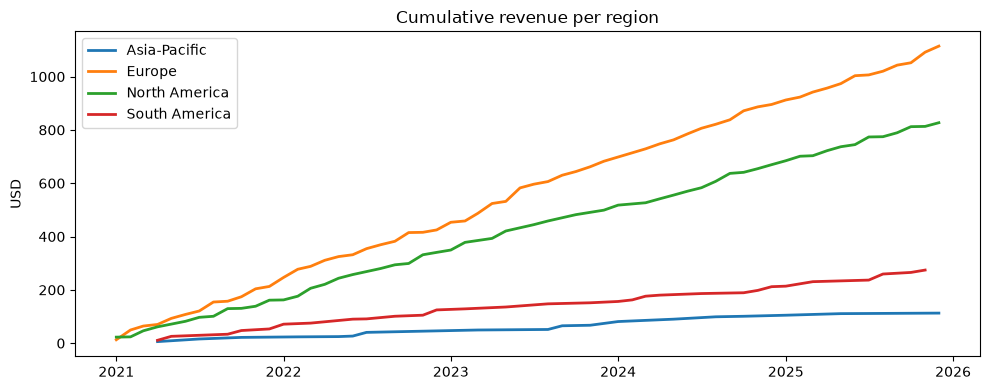

In [4]:
monthly = lq("""
WITH m AS (
    SELECT d.month_start, c.region, sum(f.revenue) AS revenue
    FROM mart.fact_sales f
    JOIN mart.dim_date d USING (date_key)
    JOIN mart.dim_customer c USING (customer_key)
    GROUP BY 1, 2
)
SELECT month_start, region, revenue,
       sum(revenue) OVER (PARTITION BY region ORDER BY month_start) AS running_total
FROM m ORDER BY region, month_start
""")
print(monthly.head(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
for region, part in monthly.groupby("region"):
    ax.plot(part["month_start"], part["running_total"].astype(float), lw=2, label=region)
ax.set(title="Cumulative revenue per region", ylabel="USD")
ax.legend()
plt.tight_layout()
plt.show()

## Task 4: 90-Day Repeat-Purchase Rate per Cohort

In [5]:
retention = lq("""
WITH purchases AS (
    SELECT DISTINCT f.customer_key, d.date
    FROM mart.fact_sales f JOIN mart.dim_date d USING (date_key)
),
firsts AS (
    SELECT customer_key, min(date) AS first_date FROM purchases GROUP BY customer_key
)
SELECT extract(year FROM fp.first_date)::int AS cohort,
       count(*) AS customers,
       count(*) FILTER (WHERE EXISTS (
           SELECT 1 FROM purchases p
           WHERE p.customer_key = fp.customer_key AND p.date > fp.first_date AND p.date <= fp.first_date + 90)) AS repeat_90d
FROM firsts fp GROUP BY 1 ORDER BY 1
""")
retention["repeat_rate"] = (retention["repeat_90d"] / retention["customers"]).round(2)
retention

,cohort,customers,repeat_90d,repeat_rate
0,2021,46,12,0.26
1,2022,13,6,0.46


Chinook has only 59 customers, so each cohort is small and the rates are noisy. In real data, you would compare many monthly cohorts over time and add a confidence interval to each rate (M06, M14).

## Task 5: Top 3 Genres per Region

In [6]:
top_genres = lq("""
WITH g AS (
    SELECT c.region, p.genre, sum(f.revenue) AS revenue
    FROM mart.fact_sales f
    JOIN mart.dim_customer c USING (customer_key)
    JOIN mart.dim_product p USING (product_key)
    GROUP BY 1, 2
)
SELECT * FROM (
    SELECT region, genre, revenue, DENSE_RANK() OVER (PARTITION BY region ORDER BY revenue DESC) AS rnk FROM g
) ranked
WHERE rnk <= 3 ORDER BY region, rnk, genre
""")
top_genres

,region,genre,revenue,rnk
0,Asia-Pacific,Rock,46.53,1
1,Asia-Pacific,Metal,15.84,2
2,Asia-Pacific,Alternative & Punk,10.89,3
3,Asia-Pacific,Latin,10.89,3
4,Europe,Rock,420.75,1
5,Europe,Latin,153.45,2
6,Europe,Alternative & Punk,127.71,3
7,North America,Rock,261.36,1
8,North America,Latin,149.49,2
9,North America,Metal,102.96,3


## Task 6: Which Region Grew the Most from 2024 to 2025?

In [7]:
growth = lq("""
WITH y AS (
    SELECT c.region, d.year, sum(f.revenue) AS revenue
    FROM mart.fact_sales f JOIN mart.dim_date d USING (date_key) JOIN mart.dim_customer c USING (customer_key)
    WHERE d.year IN (2024, 2025) GROUP BY 1, 2
)
SELECT region,
       sum(revenue) FILTER (WHERE year = 2024) AS rev_2024,
       sum(revenue) FILTER (WHERE year = 2025) AS rev_2025,
       sum(revenue) FILTER (WHERE year = 2025) - sum(revenue) FILTER (WHERE year = 2024) AS abs_change,
       round(100 * (sum(revenue) FILTER (WHERE year = 2025) / sum(revenue) FILTER (WHERE year = 2024) - 1), 1) AS pct_change
FROM y GROUP BY region ORDER BY abs_change DESC
""")
print(growth.to_string(index=False))
top_abs = growth.iloc[0]
top_rel = growth.sort_values("pct_change", ascending=False).iloc[0]
print(f"\nAnswer: {top_abs['region']} grew the most in absolute terms ({float(top_abs['abs_change']):+.2f} USD); "
      f"{top_rel['region']} grew the most in relative terms ({float(top_rel['pct_change']):+.1f} %).")

       region  rev_2024  rev_2025  abs_change  pct_change
       Europe    212.93    218.91        5.98         2.8
South America     60.39     62.37        1.98         3.3
North America    170.55    157.41      -13.14        -7.7
 Asia-Pacific     33.66     11.89      -21.77       -64.7

Answer: Europe grew the most in absolute terms (+5.98 USD); South America grew the most in relative terms (+3.3 %).


## Task 7: Index and `EXPLAIN`

The most frequent dashboard query filters the fact table on a **date range** and sums revenue by customer. A composite index on `(date_key)` that **includes** `customer_key` and `revenue` lets PostgreSQL answer from the index alone.

The cell prints the plan twice: with the default settings, and with sequential scans disabled. The second plan proves that the index is **usable** even if the planner prefers a sequential scan, which can happen on a table this small (2,240 rows).

In [8]:
run("CREATE INDEX fact_sales_date_idx ON mart.fact_sales (date_key) INCLUDE (customer_key, revenue)")
with lab.connect().execution_options(isolation_level="AUTOCOMMIT") as conn:   # VACUUM cannot run in a transaction
    conn.execute(text("VACUUM ANALYZE mart.fact_sales"))
sql = "SELECT customer_key, sum(revenue) FROM mart.fact_sales WHERE date_key BETWEEN 20250101 AND 20250331 GROUP BY 1"
with lab.begin() as conn:
    default_plan = [r[0] for r in conn.execute(text("EXPLAIN " + sql))]
    conn.execute(text("SET LOCAL enable_seqscan = off"))
    forced_plan = [r[0] for r in conn.execute(text("EXPLAIN " + sql))]
print("default plan:\n  " + "\n  ".join(default_plan))
print("\nwith enable_seqscan = off:\n  " + "\n  ".join(forced_plan))

default plan:
  HashAggregate  (cost=6.81..7.42 rows=49 width=36)
    Group Key: customer_key
    ->  Index Only Scan using fact_sales_date_idx on fact_sales  (cost=0.28..6.30 rows=101 width=9)
          Index Cond: ((date_key >= 20250101) AND (date_key <= 20250331))

with enable_seqscan = off:
  HashAggregate  (cost=6.81..7.42 rows=49 width=36)
    Group Key: customer_key
    ->  Index Only Scan using fact_sales_date_idx on fact_sales  (cost=0.28..6.30 rows=101 width=9)
          Index Cond: ((date_key >= 20250101) AND (date_key <= 20250331))


**Summary for the analytics team:** the `mart` schema reconciles exactly with the source revenue, answers the standard questions with short queries, and has an index that is ready for the date-range filters of the dashboards when the data grows.